> **UNQUANTIZED RERUN** — generated copy of `17_e0_pilot_v2.ipynb` with
> `meta-llama/Llama-3.1-8B-Instruct` (bf16, sharded via `device_map="auto"`)
> in place of the AWQ-INT4 variant. All `resources/` outputs carry the
> `_unquantized` suffix; the pair selection (`15_e0_selected_pairs.json`) is
> shared with the quantized runs so results are directly comparable.
> Hardcoded reference values quoted in comments/markdown still describe the
> AWQ runs. Original notebook left untouched.


# 17 — E0 Pilot v2: Continuous Expression Metric, k ∈ {3, 4} (Step 9 re-run)

Re-run of the E0 pilot with the lessons of notebook 16:

- **Metric v2** — continuous concept-expression: post-hoc projection of each generated
  continuation onto each concept (`fur.project`), reported as the **delta** vs the
  unsteered baseline continuation of the same prompt. Presence-success floored at 0 in
  v1 while steering visibly worked; projection sees topic alignment without requiring
  exact member lemmas, and is method-agnostic.
- **k ∈ {3, 4}** as an explicit factor (fluency cost roughly doubled from k=3 to k=4
  in earlier runs; success may trade off the same way).
- steps=24 (gentler than v1's 32), single batch order (v1: order delta = 0.000).

Matrix: 3 ρ strata × {F1.a, F2.a} × k ∈ {3,4} × 20 prompts = 240 records.

Joint measure: per-concept deltas are z-scored across all records of that concept
(projection scales are not comparable across concepts), then joint = min(z_a, z_b) —
AND semantics on the standardized scale.

Outputs: `resources/17_e0_pilot_v2.jsonl`, `resources/17_e0_summary_v2.csv`,
`resources/17_e0_gap_vs_rho_v2.png`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "meta-llama/Llama-3.1-8B-Instruct",
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
KS = (3, 4)
STEPS = 24

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())[
    "selected"
]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


2026-07-16 23:27:57.158 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: meta-llama/Llama-3.1-8B-Instruct


2026-07-16 23:27:57.161 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 15316 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/17_e0_pilot_v2_unquantized.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:01<00:00,  1.68s/it]

100%|██████████| 1/1 [00:01<00:00,  1.68s/it]

baseline ready


## The matrix

In [4]:
for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    mean_frame = Concept.average([concept_a, concept_b])
    synsets = [info["a"], info["b"]]
    concepts = {info["a"]: concept_a, info["b"]: concept_b}

    for k in KS:
        texts_f1, probe_f1 = fur.generate_with_topk_guide(
            PROMPTS, guide=mean_frame, k=k, steps=STEPS
        )
        harness.evaluate(
            PROMPTS,
            texts_f1,
            synsets,
            config={
                "stratum": stratum,
                "rho": info["rho"],
                "method": "F1.a",
                "k": k,
                "steps": STEPS,
            },
            probe=probe_f1,
            baseline_texts=baseline_texts,
            concepts=concepts,
        )

        texts_f2, probe_f2 = fur.generate_with_topk_multi_guide(
            PROMPTS, guides=[concept_a, concept_b], k=k, steps=STEPS, normalize="zscore"
        )
        harness.evaluate(
            PROMPTS,
            texts_f2,
            synsets,
            config={
                "stratum": stratum,
                "rho": info["rho"],
                "method": "F2.a",
                "k": k,
                "steps": STEPS,
            },
            probe=probe_f2,
            baseline_texts=baseline_texts,
            concepts=concepts,
        )
        print(f"{stratum} / k={k}: done")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:11<00:00, 11.98s/it]

100%|██████████| 1/1 [00:11<00:00, 11.99s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:11<00:00, 11.78s/it]

...

100%|██████████| 1/1 [00:15<00:00, 15.82s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.84s/it]

100%|██████████| 1/1 [00:15<00:00, 15.84s/it]

high / k=4: done


In [5]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * 2 * len(KS) * len(PROMPTS), "one record per cell per prompt"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 240 records parse, expression logged


## Metric v2 sanity: does steering raise expression at all?

Mean steered vs baseline expression, pooled over both concepts of each pair.

In [6]:
rows = []
for record in parsed:
    config = record["config"]
    info = SELECTION[config["stratum"]]
    expr = record["expression"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "k": config["k"],
            "concept_a": info["a"],
            "concept_b": info["b"],
            "delta_a": expr[info["a"]]["delta"],
            "delta_b": expr[info["b"]]["delta"],
            "steered_a": expr[info["a"]]["steered"],
            "baseline_a": expr[info["a"]]["baseline"],
            "steered_b": expr[info["b"]]["steered"],
            "baseline_b": expr[info["b"]]["baseline"],
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
            "success_both": all(record["success"].values()),
        }
    )
results = pd.DataFrame(rows)

sanity = results[["delta_a", "delta_b"]].mean()
print("mean expression delta (steered - baseline):")
print(sanity.round(4))
print("\nshare of records with positive delta:")
print(((results[["delta_a", "delta_b"]] > 0).mean()).round(3))

mean expression delta (steered - baseline):
delta_a    0.6600
delta_b    0.4939
dtype: float64

share of records with positive delta:
delta_a    0.742
delta_b    0.650
dtype: float64


## Joint expression gain (standardized min) and summary

In [7]:
# z-score each concept's delta across all its records (per-concept scales differ),
# then joint = min of the two z-scores (AND semantics)
for side in ("a", "b"):
    zs = []
    for concept, group in results.groupby(f"concept_{side}")[f"delta_{side}"]:
        z = (group - group.mean()) / (group.std() + 1e-8)
        zs.append(z)
    results[f"z_{side}"] = pd.concat(zs).sort_index()
results["joint_z"] = results[["z_a", "z_b"]].min(axis=1)

summary = (
    results.groupby(["stratum", "rho", "method", "k"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint_z=("joint_z", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
        presence_both=("success_both", "mean"),
    )
    .reset_index()
    .sort_values(["k", "rho", "method"])
)
summary.to_csv("resources/17_e0_summary_v2_unquantized.csv", index=False)
summary.round(4)

,stratum,rho,method,k,delta_a,delta_b,joint_z,ppl_ratio,flag_share,presence_both
4,low,0.1867,F1.a,3,0.6872,0.2711,-0.1415,6.7470,0.85,0.0
6,low,0.1867,F2.a,3,0.1692,0.1159,-0.4510,6.6749,0.90,0.0
8,medium,0.3213,F1.a,3,0.5144,0.4318,-0.1423,4.8284,0.80,0.0
10,medium,0.3213,F2.a,3,0.4524,0.3518,-0.2154,5.7099,0.85,0.0
0,high,0.5661,F1.a,3,0.2456,0.3442,-0.5374,5.8139,0.95,0.0
2,high,0.5661,F2.a,3,0.6574,0.6426,-0.2657,5.3243,0.85,0.0
5,low,0.1867,F1.a,4,0.8798,0.1905,-0.1601,8.1433,0.95,0.0
7,low,0.1867,F2.a,4,0.4635,0.3805,-0.2586,7.1892,0.90,0.0
9,medium,0.3213,F1.a,4,0.6049,0.4284,-0.1395,7.4077,0.85,0.0
11,medium,0.3213,F2.a,4,0.8099,0.8202,0.0619,6.1153,0.80,0.0


## THE plot v2 — gap vs ρ, per k

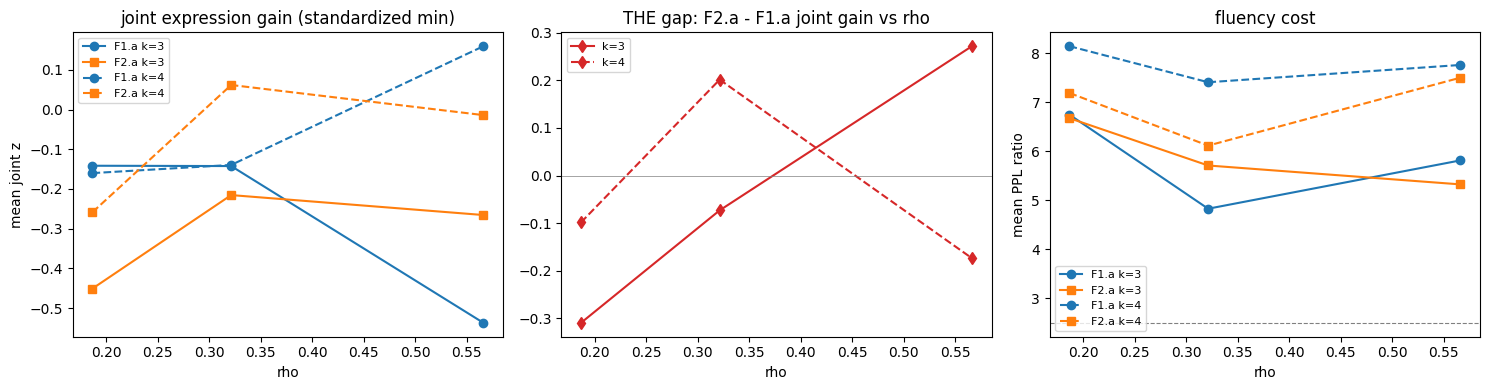

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
styles = {3: "-", 4: "--"}

for k in KS:
    sub = summary[summary["k"] == k]
    f1 = sub[sub["method"] == "F1.a"].set_index("rho").sort_index()
    f2 = sub[sub["method"] == "F2.a"].set_index("rho").sort_index()
    rhos = list(f1.index)

    axes[0].plot(
        rhos, f1["joint_z"], "o" + styles[k], color="tab:blue", label=f"F1.a k={k}"
    )
    axes[0].plot(
        rhos, f2["joint_z"], "s" + styles[k], color="tab:orange", label=f"F2.a k={k}"
    )

    axes[1].plot(
        rhos,
        (f2["joint_z"] - f1["joint_z"]),
        "d" + styles[k],
        color="tab:red",
        label=f"k={k}",
    )

    axes[2].plot(
        rhos, f1["ppl_ratio"], "o" + styles[k], color="tab:blue", label=f"F1.a k={k}"
    )
    axes[2].plot(
        rhos, f2["ppl_ratio"], "s" + styles[k], color="tab:orange", label=f"F2.a k={k}"
    )

axes[0].set_title("joint expression gain (standardized min)")
axes[0].set_ylabel("mean joint z")
axes[1].set_title("THE gap: F2.a - F1.a joint gain vs rho")
axes[1].axhline(0, color="gray", lw=0.5)
axes[2].set_title("fluency cost")
axes[2].set_ylabel("mean PPL ratio")
axes[2].axhline(2.5, color="gray", ls="--", lw=0.8)
for ax in axes:
    ax.set_xlabel("rho")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("resources/17_e0_gap_vs_rho_v2_unquantized.png", dpi=150)
plt.show()

## Examples

In [9]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for method in ("F1.a", "F2.a"):
        example = next(
            r
            for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["method"] == method
            and r["config"]["k"] == 3
            and "short story" in r["prompt"]
        )
        deltas = {
            name.split(".")[0]: round(v["delta"], 4)
            for name, v in example["expression"].items()
        }
        print(f"[{stratum} / {method} / k=3] deltas={deltas}")
        print("   ", answer(example["text"])[:130])
    print()

[low / F1.a / k=3] deltas={'sadness': 0.7019, 'music': 0.5873}
    Once, in an old antique shop nestled between a used recordstoreand apopcornstandon MainStreet,U.S.A.,there
[low / F2.a / k=3] deltas={'sadness': 0.057, 'music': -1.3466}
    Once, on an island surrounded only sea on all its side. There existed an old man who lived alone. The old was a

[medium / F1.a / k=3] deltas={'woman': 0.3587, 'king': -0.2161}
    Once, there lived a young artist in Paris, a small apartment on the Seines' left bank. Her studio window overlooked the
[medium / F2.a / k=3] deltas={'woman': 0.5707, 'king': -0.5547}
    Once, in an old antique shop, a young girl stumbled across an old musicbox. It had intricate carves of vines and

[high / F1.a / k=3] deltas={'sorrow': 0.2807, 'sadness': 0.0193}
    Once, on an isolated coast in Japan, there was small, weather-won village nestled in between towering mountains. For years,
[high / F2.a / k=3] deltas={'sorrow': -0.0727, 'sadness': -0.164}
    Once, on an i